# D2_03 ANOVA · PCA · 요인분석

> **오늘 질문:** 제품 등급에 따라 공정이 다른가? 590개 센서를 몇 개의 축으로 요약할 수 있을까?

| 파트 | 데이터 | 방법 |
|---|---|---|
| 1 | 공장 분석 테이블 | 등급(L·M·H)별 ANOVA + 사후검정 |
| 2 | SECOM (반도체 센서 590개) | PCA |
| 3 | Steel Plates (강판 결함) | 요인분석 |

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import FactorAnalyzer

df = pd.read_parquet("../../data/factory_table.parquet")
secom = pd.read_csv("../../data/secom.csv")
steel = pd.read_csv("../../data/steel_plates.csv")

## 1. 등급별 ANOVA: 토크 ✍️

세 그룹을 t-test로 여러 번 비교하면 '우연한 유의'가 늘어납니다. ANOVA로 한 번에 검정합니다.

> 변수 이름: `L`, `M`, `H`

In [2]:
df

,record_id,timestamp,equip_id,line,product_id,grade,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure,twf,hdf,pwf,osf,rnf
0,1,2025-01-01 00:00:00,MC-08,L2,M14860,M,25.0,35.5,1551,42.8,0,1.84,0,0,0,0,0,0
1,2,2025-01-01 00:14:24,MC-08,L2,L47181,L,25.1,35.6,1408,46.3,3,2.20,0,0,0,0,0,0
2,3,2025-01-01 00:28:48,MC-03,L1,L47182,L,25.0,35.4,1498,49.4,5,1.86,0,0,0,0,0,0
3,4,2025-01-01 00:43:12,MC-01,L1,L47183,L,25.1,35.5,1433,39.5,7,2.51,0,0,0,0,0,0
4,5,2025-01-01 00:57:36,MC-04,L1,L47184,L,25.1,35.6,1408,40.0,9,2.05,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,2025-04-10 22:48:00,MC-09,L2,M24855,M,25.7,35.2,1604,29.5,14,2.35,0,0,0,0,0,0
9996,9997,2025-04-10 23:02:24,MC-06,L2,H39410,H,25.8,35.2,1632,31.8,17,2.16,0,0,0,0,0,0
9997,9998,2025-04-10 23:16:48,MC-09,L2,M24857,M,25.9,35.5,1645,33.4,22,2.44,0,0,0,0,0,0
9998,9999,2025-04-10 23:31:12,MC-07,L2,H39412,H,25.9,35.6,1408,48.5,25,2.15,0,0,0,0,0,0


In [3]:
# 힌트: stats.f_oneway(그룹1, 그룹2, 그룹3)
L = df[ df['grade'] == "L" ]
M = df[ df['grade'] == "M" ]
H = df[ df['grade'] == "H" ]
stats.f_oneway(L['torque'], M['torque'], H['torque'])
# pvalue=0.8797120606699937 <-- pvalue가 0.05 보다 커서 차이가 없다. H0

F_onewayResult(statistic=0.12816227185961, pvalue=0.8797120606699937)

In [4]:
df.groupby("grade")['torque'].agg(["count", "mean", "std"]).round(2)

,count,mean,std
grade,,,
H,1003,39.84,9.64
L,6000,40.00,10.01
M,2997,40.02,9.99


## 2. 등급별 ANOVA: 진동 ✍️

같은 방법으로 진동을 비교하고, 등급별 평균도 함께 봅니다.

In [5]:
print(stats.f_oneway(L['vibration'], M['vibration'], H['vibration']))
# pvalue=0.0005497985734896173 <-- 0.05 보다 작으니 차이가 있다. H1
df.groupby('grade')['vibration'].mean().round(3)

F_onewayResult(statistic=7.511597030893859, pvalue=0.0005497985734896173)


grade
H    2.049
L    2.087
M    2.086
Name: vibration, dtype: float64

## 3. 사후검정: 어디가 다른가 ✍️

ANOVA가 유의하면 Tukey HSD로 어느 쌍이 다른지 봅니다. `reject`가 True인 쌍이 차이가 있는 쌍입니다.

In [6]:
# 힌트: pairwise_tukeyhsd(값, 그룹), p-adj가 p-value.
print(pairwise_tukeyhsd(df['vibration'], df['grade']))
# Multiple Comparison of Means - Tukey HSD, FWER=0.05
# ===================================================
# group1 group2 meandiff p-adj   lower  upper  reject
# ---------------------------------------------------
#      H      L   0.0371 0.0004  0.0142   0.06   True <-- 차이가 있다(p-adj 0.0004) : 0.05보다 작다
#      H      M   0.0366 0.0013  0.0121 0.0611   True <-- 차이가 있다(p-adj 0.0013)
#      L      M  -0.0005 0.9962 -0.0155 0.0145  False <-- 차이가 없다(p-adj 0.9962)
# ---------------------------------------------------

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     H      L   0.0371 0.0004  0.0142   0.06   True
     H      M   0.0366 0.0013  0.0121 0.0611   True
     L      M  -0.0005 0.9962 -0.0155 0.0145  False
---------------------------------------------------


**Q1.** 토크와 진동의 ANOVA 결과를 각각 해석해 보세요. 진동 차이는 현장에서 중요할까요?

> 답:


## 4. SECOM 전처리 📋

PCA 전에 ① 결측을 채우고 ② 표준화(평균 0, 표준편차 1)합니다. 단위가 다른 센서를 공평하게 다루기 위해서입니다.

In [5]:
try:
    import mglearn
except:
    %pip install mglearn
    import mglearn

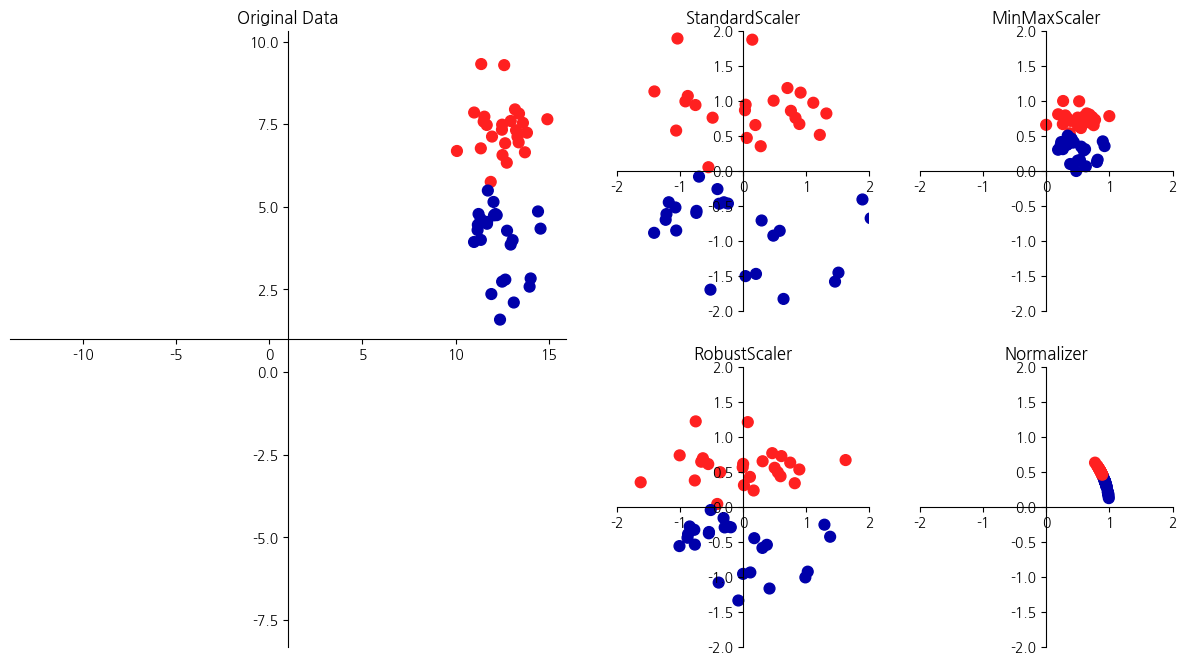

In [8]:
mglearn.plots.plot_scaling()

In [9]:
from sklearn.preprocessing import MinMaxScaler

X = secom.drop(columns=["timestamp", "defect"])
X = X.fillna(X.median())

scaler = MinMaxScaler()
X_scaled1 = scaler.fit_transform(X)

print("최솟값:", X_scaled1.min())
print("최댓값:", X_scaled1.max())

최솟값: 0.0
최댓값: 1.0000000000000009


In [10]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

X = secom.drop(columns=["timestamp", "defect"])
X = X.fillna(X.median())

X_scaled2 = StandardScaler().fit_transform(X)

print("최솟값:", X_scaled2.min())
print("최댓값:", X_scaled2.max())
print("평균:", X_scaled2.mean())

# -2 ~ 2 범위를 벗어난 값의 비율
outside = np.abs(X_scaled2) > 2

print(f"±2 범위 밖: {outside.mean():.2%}")
print(f"±3 범위 밖: {(np.abs(X_scaled2) > 3).mean():.2%}")

최솟값: -37.92346528716161
최댓값: 39.572717874818785
평균: -2.865596188933955e-16
±2 범위 밖: 2.41%
±3 범위 밖: 0.74%


In [11]:
X = secom.drop(columns=["timestamp", "defect"])
print(f"센서 {X.shape[1]}개, 결측 {X.isna().sum().sum():,}칸")

X = X.fillna(X.median())                       # 결측은 각 센서의 중앙값으로
X_scaled = StandardScaler().fit_transform(X)   # 표준화

센서 590개, 결측 41,951칸


## 5. PCA와 누적 설명 분산 ✍️

`explained_variance_ratio_`는 각 주성분이 담은 정보의 비율입니다. `cumsum()`으로 누적합니다.

> 변수 이름: `pca`, `cum`

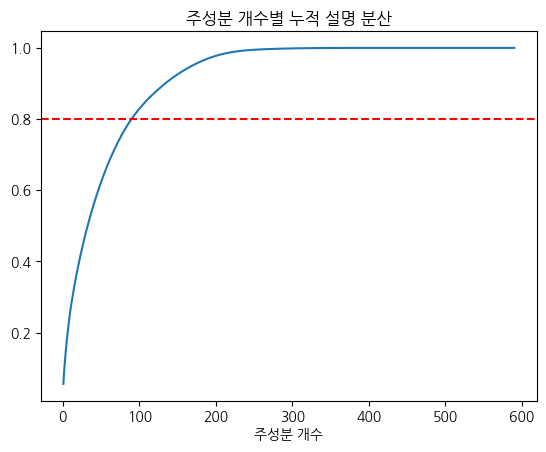

In [12]:
# 힌트: PCA().fit(데이터), pca.explained_variance_ratio_.cumsum()
pca = PCA().fit(X_scaled)
cum = pca.explained_variance_ratio_.cumsum()
plt.plot(range(1, len(cum) + 1), cum)
plt.axhline(0.8, color="red", linestyle="--")
plt.title("주성분 개수별 누적 설명 분산")
plt.xlabel("주성분 개수")
plt.show()

누적 80%에 도달하는 주성분 개수를 셉니다.

In [13]:
n80 = (cum < 0.8).sum() + 1
print(f"80%를 설명하는 주성분: {n80}개의 (센서 {X.shape[1]}개)")

80%를 설명하는 주성분: 90개의 (센서 590개)


**Q2.** 590개 센서를 몇 개의 주성분으로 요약할 수 있나요? PC1 하나가 담은 정보는 얼마나 되나요?

> 답:


## 6. 요인분석: 강판 결함 데이터 📋

강판 결함의 크기·둘레·밝기 관련 변수 7개로 요인 2개를 찾습니다. 결과 표(요인 적재량)를 읽는 것이 목표입니다.

In [14]:
cols = ["pixels_areas", "x_perimeter", "y_perimeter", "sum_of_luminosity",
        "minimum_of_luminosity", "maximum_of_luminosity", "luminosity_index"]

fa = FactorAnalyzer(n_factors=2, rotation="varimax", method="principal").fit(steel[cols])
eigen, _ = fa.get_eigenvalues()
print("고유값:", eigen.round(2))

loadings = pd.DataFrame(fa.loadings_, index=cols, columns=["요인1", "요인2"])
loadings.round(2)

고유값: [3.92 2.26 0.58 0.17 0.05 0.02 0.  ]


,요인1,요인2
pixels_areas,0.99,-0.06
x_perimeter,0.99,-0.02
y_perimeter,0.87,0.01
sum_of_luminosity,0.96,-0.05
minimum_of_luminosity,-0.45,0.73
maximum_of_luminosity,0.17,0.91
luminosity_index,-0.00,0.97


**Q3.** 적재량이 0.4 이상인 변수를 보고 요인1과 요인2에 이름을 붙여 보세요. 고유값으로 보면 요인 2개가 적절한가요?

> 답:
